# Chapitre 10 - Cours 4 : Les retours utilisateurs

On peut raisonner longtemps sur la façon de construire une bonne application : la seule
manière de savoir si elle atteint son but est de la mettre entre les mains des
utilisateurs. Pour une application d'IA, leurs retours servent doublement : ils **évaluent**
le produit et ils constituent des **données** pour améliorer les modèles. L'interface
conversationnelle facilite le retour (on corrige l'assistant comme on corrigerait un
collègue), mais rend l'extraction des signaux plus difficile.

Sections du livre couvertes : *User Feedback*, *Extracting Conversational Feedback*
(*Natural language feedback*, *Other conversational feedback*), *Feedback Design*
(*When to collect feedback*, *How to collect feedback*), *Feedback Limitations*
(*Biases*, *Degenerate feedback loop*).

Plan :
1. les retours sont des données ;
2. retours explicites et implicites ;
3. extraire des signaux d'une conversation : heuristiques ;
4. extraire des signaux avec un petit LLM ;
5. la trajectoire du sentiment ;
6. concevoir la collecte des retours ;
7. les biais des retours ;
8. les boucles de rétroaction dégénérées.

In [1]:
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, confusion_matrix
from aie.plotting import set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, COLORS, annotate_bars
from aie.diagrams import Diagram
from aie import llm
from aie import ch10_architecture as A

set_style()
pd.set_option("display.max_colwidth", 80)
rng = np.random.default_rng(0)
embed = lambda texts: llm.embed(texts, llm.EMBED_MULTI)

## 1. Les retours sont des données (section *User Feedback*)

Les retours utilisateurs sont des **données propriétaires**, et les données sont un
avantage concurrentiel : un produit lancé tôt attire des utilisateurs, collecte leurs
retours, améliore ses modèles, attire plus d'utilisateurs... C'est le **volant d'inertie
des données** (« data flywheel ») du chapitre 8. Le livre note qu'une application open
source a du mal à en profiter : chacun la déploie chez soi et l'auteur ne voit rien.

Rappel essentiel : un retour utilisateur **est** une donnée utilisateur. Vie privée,
consentement et transparence sur l'usage s'appliquent.

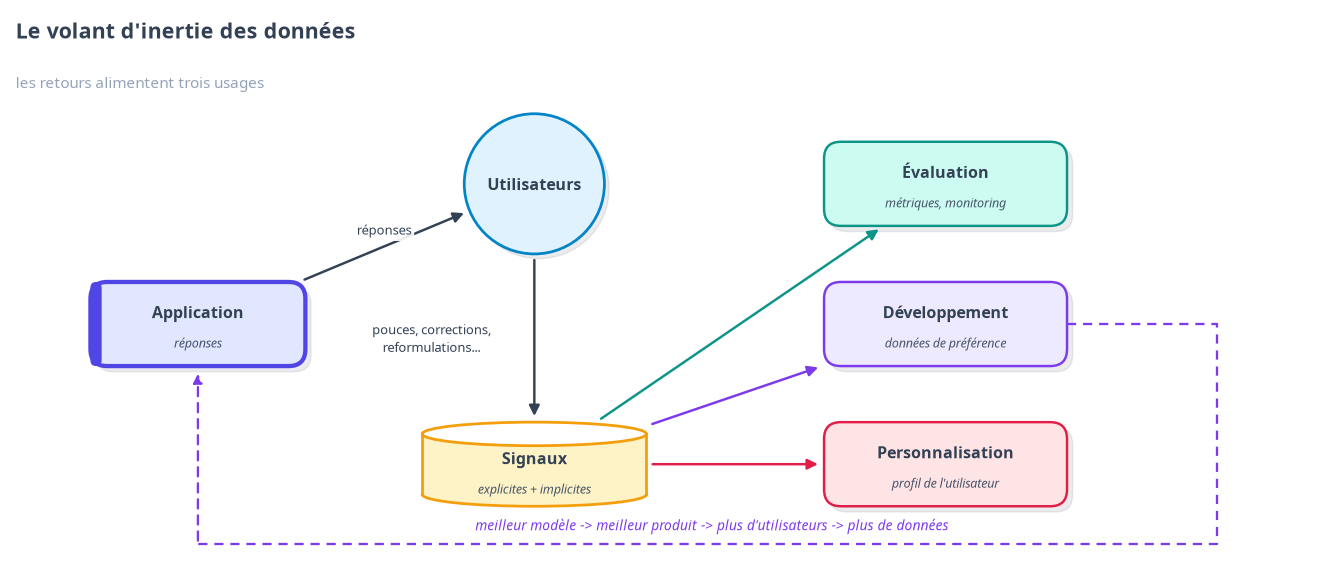

In [2]:
d = Diagram(14, 5.0, title="Le volant d'inertie des données", subtitle="les retours alimentent trois usages")
d.box("app", 2.0, 2.6, "Application", sub="réponses", color=INDIGO, kind="model", w=2.3)
d.box("users", 5.6, 4.1, "Utilisateurs", color=SKY, kind="user", w=1.5)
d.box("fb", 5.6, 1.1, "Signaux", sub="explicites + implicites", color=AMBER, kind="db", w=2.4)
d.box("eval", 10.0, 4.1, "Évaluation", sub="métriques, monitoring", color=TEAL, w=2.6)
d.box("dev", 10.0, 2.6, "Développement", sub="données de préférence", color=VIOLET, w=2.6)
d.box("perso", 10.0, 1.1, "Personnalisation", sub="profil de l'utilisateur", color=ROSE, w=2.6)
d.arrow("app", "users", "réponses")
d.arrow("users", "fb", "pouces, corrections,\nreformulations...", label_offset=(-1.1, 0))
d.arrow("fb", "eval", color=TEAL); d.arrow("fb", "dev", color=VIOLET); d.arrow("fb", "perso", color=ROSE)
d.line([(11.3, 2.6), (12.9, 2.6), (12.9, 0.25), (2.0, 0.25), (2.0, 2.1)], color=VIOLET, style="dashed", lw=1.5)
d.note(7.5, 0.45, "meilleur modèle -> meilleur produit -> plus d'utilisateurs -> plus de données", color=VIOLET, fontsize=9)
d.show()

> **À retenir.** Les retours servent à évaluer, développer et personnaliser ; ils sont la
> matière première du volant d'inertie des données, et restent des données personnelles.

## 2. Retours explicites et implicites (section *Extracting Conversational Feedback*)

- **Explicites** : l'utilisateur répond à une demande (pouce levé ou baissé, étoiles,
  « avons-nous résolu votre problème ? »). Faciles à interpréter, bien standardisés, mais
  **rares** (effort demandé) et **biaisés** (les mécontents répondent davantage).
- **Implicites** : déduits des actions (acheter le produit recommandé, copier le code,
  reformuler, abandonner). **Abondants**, mais **bruités** et propres à chaque application.

Exemple du livre : à trois suggestions d'hôtels à Sydney, répondre « réserve celui près des
galeries » révèle un goût pour l'art, tandis que « il n'y a rien sous 200 dollars ? » révèle
une sensibilité au prix et le fait que l'assistant n'a pas encore cerné l'utilisateur.

**Rare et propre, ou abondant et bruité ?** Simulons l'estimation du taux de satisfaction
réel (70 %) avec 2 000 conversations par jour. Retour explicite : 3 % des satisfaits et
10 % des insatisfaits répondent, sans erreur. Signal implicite : disponible pour tous, mais
ne dit vrai que dans 75 % des cas ; on le corrige en connaissant cette exactitude
(si $s$ est la part de signaux positifs et $a$ l'exactitude, $\hat p = (s - (1-a))/(2a-1)$).

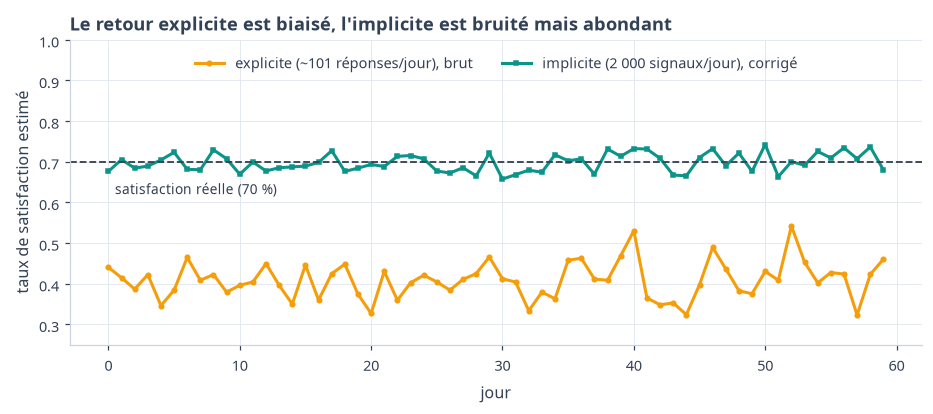

In [3]:
p_true, n_days = 0.70, 60
est_exp, est_imp, n_exp = [], [], []
for day in range(n_days):
    r = np.random.default_rng(day)
    happy = r.random(2000) < p_true
    gives = r.random(2000) < np.where(happy, 0.03, 0.10)
    est_exp.append(happy[gives].mean()); n_exp.append(gives.sum())
    a = 0.75
    sig = np.where(r.random(2000) < a, happy, ~happy)
    est_imp.append((sig.mean() - (1 - a)) / (2 * a - 1))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(est_exp, "o-", color=AMBER, ms=3, label=f"explicite (~{np.mean(n_exp):.0f} réponses/jour), brut")
ax.plot(est_imp, "s-", color=TEAL, ms=3, label="implicite (2 000 signaux/jour), corrigé")
ax.axhline(p_true, color=SLATE, ls="--", lw=1.2); ax.text(0.5, p_true - 0.08, "satisfaction réelle (70 %)", color=SLATE, fontsize=9)
ax.set(xlabel="jour", ylabel="taux de satisfaction estimé", ylim=(0.25, 1.0),
       title="Le retour explicite est biaisé, l'implicite est bruité mais abondant")
ax.legend(loc="upper center", ncol=2); plt.show()

Le retour explicite est **systématiquement trop pessimiste** (biais de sélection : les
mécontents s'expriment plus) et fluctue avec peu de réponses ; le signal implicite, bien
que faux une fois sur quatre, donne une estimation non biaisée **si l'on connaît son
exactitude** (ce qui suppose une étude de calibration sur des conversations annotées). En
pratique on combine les deux.

> **À retenir.** Explicite : interprétable mais rare et biaisé. Implicite : abondant mais
> bruité et ambigu. Les deux se complètent.

## 3. Extraire des signaux d'une conversation : heuristiques (sections *Natural language feedback* et *Other conversational feedback*)

Le livre recense les signaux à suivre en production :
- **arrêt précoce** : l'utilisateur interrompt la génération, quitte l'application, dit
  « stop », ou laisse l'agent sans réponse ;
- **correction d'erreur** : message qui commence par « Non, ... » ou « Je voulais dire... »,
  **reformulation** de la demande, indications précises (« Bill est le suspect, pas la
  victime »), demandes de confirmation (« tu es sûr ? », « montre tes sources »), et
  **éditions** de la réponse (signal très fort, et paire de préférences gratuite) ;
- **plaintes** : réponse fausse, hors sujet, trop longue, pas assez détaillée... ;
- **sentiment** : frustration (« pff »), ou au contraire une colère qui se calme ;
- **refus du modèle** (« en tant qu'IA, je ne peux pas ») ;
- côté actions : **régénération**, organisation (supprimer, renommer, partager, mettre en
  favori), **longueur** de la conversation et **diversité** du dialogue (un bot qui se
  répète).

Notre fonction `A.extract_signals` implémente ces heuristiques (motifs sur le texte
normalisé, lexique de sentiment, similarité entre messages successifs pour les
reformulations, métadonnées d'interruption et de régénération). Voici une conversation du
jeu `A.CONVERSATIONS` (12 conversations annotées satisfait / insatisfait).

In [4]:
def show_conv(conv):
    for m in conv:
        tag = " [interrompue]" if m.get("interrupted") else (f" [action : {m['action']}]" if m.get("action") else "")
        print(f"{'U' if m['role'] == 'user' else 'A'}{tag} : {textwrap.shorten(m['content'], 110)}")

conv, lab = A.CONVERSATIONS[11]
show_conv(conv); print("\nétiquette :", "satisfait" if lab else "insatisfait")
pd.Series(A.extract_signals(conv)).round(2).to_frame("signal").T

U : Combien coûte la livraison ?
A [interrompue] : La livraison dépend de nombreux facteurs, notamment la destination, le poids, le mode de transport [...]
U : Stop. Combien coûte la livraison en France ?
A : Elle est gratuite dès 50 euros d'achat.
U : Trop long pour une réponse aussi simple

étiquette : insatisfait


,tours,reformulations,corrections,demandes_confirmation,plaintes,interruptions,regenerations,refus_modele,sentiment_moyen,sentiment_final,diversite_bot
signal,3.0,1.0,0.0,0.0,1.0,2.0,0.0,0.0,0.0,0.0,1.0


**Détecter une reformulation.** Deux messages successifs de l'utilisateur très similaires
indiquent souvent que la première réponse a manqué sa cible (figure 10-12 du livre). La
similarité lexicale (trigrammes) rate les reformulations qui changent les mots ; la
similarité d'embeddings les capte mieux mais confond aussi des relances légitimes sur le
même sujet. Comparons les deux sur des paires annotées.

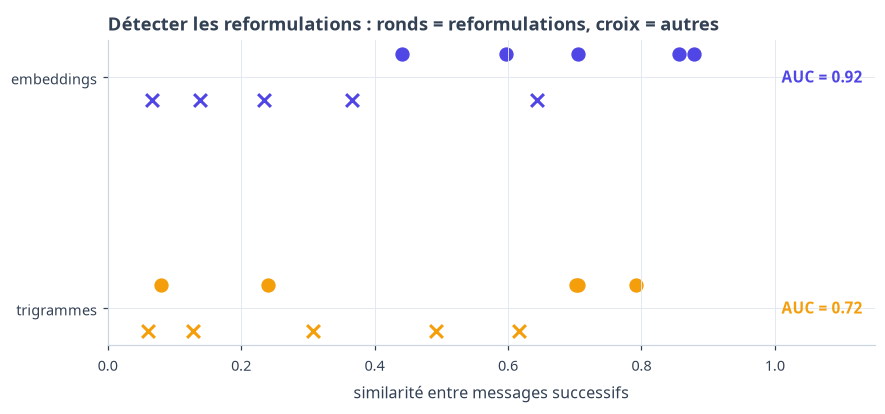

In [5]:
paires = [
    ("La batterie de mon téléphone se vide vite", "Pff, la batterie de mon téléphone se décharge très vite, que faire ?", 1),
    ("Je veux retourner un article", "Non, je veux juste savoir comment retourner un article", 1),
    ("Combien coûte la livraison ?", "Stop. Combien coûte la livraison en France ?", 1),
    ("J'ai oublié mon mot de passe", "Je n'arrive plus à me connecter, que faire pour récupérer l'accès ?", 1),
    ("Quel est le prix du casque ?", "Combien coûte ce casque audio ?", 1),
    ("Où est le magasin de Lyon ?", "Et le lundi c'est fermé ?", 0),
    ("Puis-je payer en plusieurs fois ?", "Tu es sûr ? Même pour une télé à 140 euros ?", 0),
    ("Quelle est la garantie d'une télévision ?", "Et pour un smartphone, quelle est la garantie ?", 0),
    ("Mon casque ne s'appaire pas", "Super, ça marche, merci beaucoup", 0),
    ("Livrez-vous en Belgique ?", "Et en Suisse, vous livrez ?", 0),
]
a_txt, b_txt, y_pair = zip(*paires)
Ea, Eb = embed(list(a_txt)), embed(list(b_txt))
sim_emb = (Ea * Eb).sum(1)
Ha, Hb = A.hash_embed(list(a_txt)), A.hash_embed(list(b_txt))
sim_hash = (Ha * Hb).sum(1)
fig, ax = plt.subplots(figsize=(9, 3.6))
y_pair = np.array(y_pair)
for k, (s, name, c) in enumerate([(sim_hash, "trigrammes", AMBER), (sim_emb, "embeddings MiniLM", INDIGO)]):
    ax.scatter(s[y_pair == 1], np.full((y_pair == 1).sum(), k + 0.1), color=c, s=70, marker="o", label=f"{name} : reformulation")
    ax.scatter(s[y_pair == 0], np.full((y_pair == 0).sum(), k - 0.1), color=c, s=70, marker="x", label=f"{name} : autre message")
    ax.text(1.01, k, f"AUC = {roc_auc_score(y_pair, s):.2f}", va="center", fontsize=10, color=c, fontweight="bold")
ax.set_yticks([0, 1], ["trigrammes", "embeddings"]); ax.set_xlim(0, 1.15); ax.set_xlabel("similarité entre messages successifs")
ax.set_title("Détecter les reformulations : ronds = reformulations, croix = autres")
plt.show()

Les embeddings séparent mieux les deux classes, mais pas parfaitement : « et pour un
smartphone, quelle est la garantie ? » ressemble beaucoup à la question précédente sans être
une reformulation. Une règle robuste combine plusieurs indices (similarité élevée **et**
marqueur de correction, ou interruption juste avant).

Calculons maintenant tous les signaux pour les 12 conversations, avec les embeddings pour
les reformulations, et combinons-les en un **score de satisfaction implicite**
(combinaison linéaire à poids choisis à la main, `A.SIGNAL_WEIGHTS`).

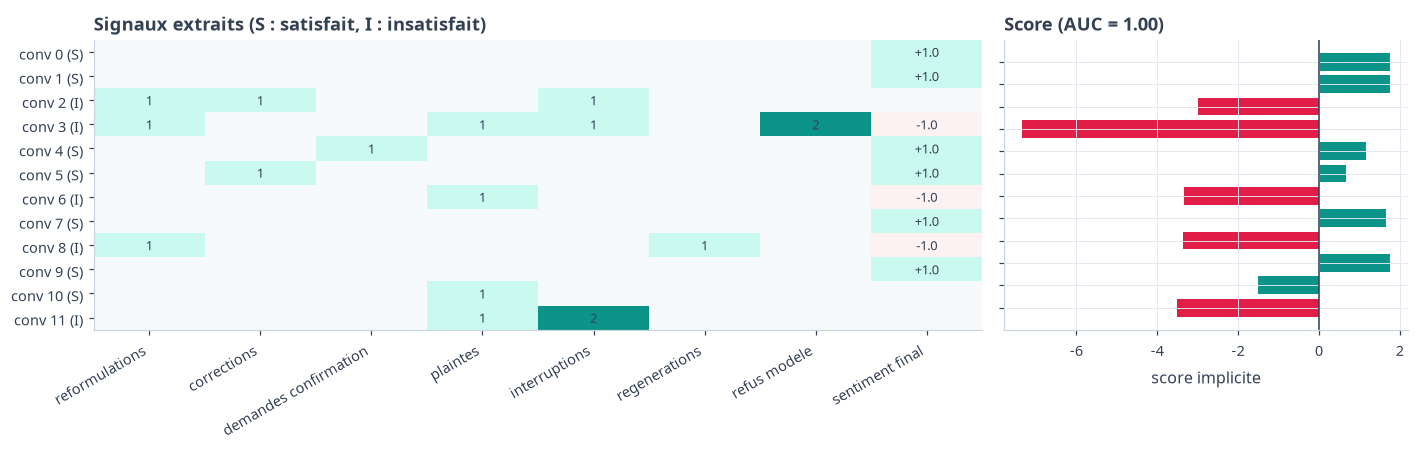

In [6]:
def sim_fn(a, b):
    E = embed([a, b]); return float(E[0] @ E[1])

rows = []
for i, (conv, lab) in enumerate(A.CONVERSATIONS):
    s = A.extract_signals(conv, sim_fn=sim_fn, rephrase_threshold=0.75)
    rows.append({"conv": i, "satisfait": lab, **s, "score": A.implicit_score(s)})
sig = pd.DataFrame(rows).set_index("conv")
show = ["reformulations", "corrections", "demandes_confirmation", "plaintes", "interruptions", "regenerations",
        "refus_modele", "sentiment_final"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
M = sig[show].values.astype(float)
ax[0].imshow(M, cmap="aie_div", vmin=-2, vmax=2, aspect="auto"); ax[0].grid(False)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if M[i, j]:
            ax[0].text(j, i, f"{M[i, j]:.0f}" if j < len(show) - 1 else f"{M[i, j]:+.1f}", ha="center", va="center", fontsize=8.5)
ax[0].set_xticks(range(len(show)), [s.replace("_", " ") for s in show], rotation=30, ha="right")
ax[0].set_yticks(range(len(sig)), [f"conv {i} ({'S' if l else 'I'})" for i, l in zip(sig.index, sig.satisfait)])
ax[0].set_title("Signaux extraits (S : satisfait, I : insatisfait)")
cols = [TEAL if l else ROSE for l in sig.satisfait]
ax[1].barh(range(len(sig)), sig.score, color=cols); ax[1].invert_yaxis(); ax[1].axvline(0, color=SLATE, lw=1)
ax[1].set_yticks(range(len(sig)), [""] * len(sig))
ax[1].set(xlabel="score implicite", title=f"Score (AUC = {roc_auc_score(sig.satisfait, sig.score):.2f})")
plt.tight_layout(); plt.show()

Les conversations insatisfaites (barres roses) cumulent reformulations, interruptions,
plaintes et sentiment final négatif. Sur ce petit jeu, le score **classe** correctement
toutes les conversations (AUC de 1), mais avec un seuil naturel à 0 il se tromperait sur
une conversation satisfaite qui contient une plainte en cours de route (« c'est pas clair,
quel pilote ? ») puis un neutre « ok je vais essayer » : son score est négatif. Le seuil,
comme les poids, doit être calibré. Le livre insiste : l'intuition donne un premier jeu de signaux, mais il faut des
**analyses de données et des études utilisateurs** pour valider leur interprétation. Avec
12 conversations, ce n'est qu'une illustration ; l'exercice 10.10 apprend les poids.

> **À retenir.** Interruptions, corrections, reformulations, plaintes, sentiment, refus et
> régénérations se détectent par heuristiques ou petits modèles ; aucun signal isolé n'est
> fiable, leur combinaison l'est davantage.